# CALOR Y MAYORES EN MADRID

## Simulador de arbolado: ¿cuánto bajaría la temperatura del entorno de cada centro si se plantan árboles?

**Modelo:** Gradient Boosting final (models/modelo_gradient_boosting.pkl).
**Escenarios:** aumento del % de copa de árboles en el hexágono de cada centro:
- bajo (corto plazo): +5 puntos
- moderado (medio plazo): +10 puntos
- ambicioso (largo plazo): +20 puntos

El "plazo" se refiere a la ambición de la intervención, no al tiempo que tardan en crecer los árboles.

## 1. Preparación

- importamos las librerías

In [15]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import LinearRegression

sys.path.append("../scrips")
from config import RUTA_CLEAN
from simulador import simular_centros

- cargamos el modelo final con su lista de features y la mediana del año de train

In [2]:
paquete_modelo = joblib.load("../models/modelo_gradient_boosting.pkl")
modelo = paquete_modelo["modelo"]
features = paquete_modelo["features"]
mediana_anio_train = paquete_modelo["mediana_anio_train"]

print("Features:", len(features))
print("Mediana del año (train):", mediana_anio_train)

Features: 14
Mediana del año (train): 1978.0


**Observación:** el modelo usa 14 features; los años vacíos se rellenarán con la mediana de train (1978), igual que al entrenar.

- cargamos los hexágonos urbanos y rellenamos los nulos igual que en el entrenamiento

In [3]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
hexagonos = hexagonos_todos[hexagonos_todos["urbano"]].copy()

hexagonos["plantas_media"] = hexagonos["plantas_media"].fillna(0)
hexagonos["altura_arboles"] = hexagonos["altura_arboles"].fillna(0)
hexagonos["anio_medio"] = hexagonos["anio_medio"].fillna(mediana_anio_train)

print(hexagonos.shape)
print("Nulos en las features:", hexagonos[features].isnull().sum().sum())

(2931, 21)
Nulos en las features: 0


**Observación:** 2.931 hexágonos urbanos, sin nulos en las features.

- asignamos a cada centro de mayores su hexágono

In [4]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
centros = gpd.sjoin(centros, hexagonos[["h3", "geometry"]], how="left", predicate="within")
centros = centros.drop(columns=["index_right"])

print("Centros:", len(centros), "- sin hexágono:", centros["h3"].isnull().sum())
print("Hexágonos con algún centro:", centros["h3"].nunique())

Centros: 439 - sin hexágono: 0
Hexágonos con algún centro: 318


**Observación:** los 439 centros tienen hexágono y se reparten en 318 hexágonos distintos, porque varios comparten edificio o manzana (por ejemplo, una residencia y un centro de día en el mismo edificio)

## 2. Relación entre copa de árboles y NDVI

**Decisión:** plantar árboles aumenta a la vez la copa y la vegetación que mide el satélite (NDVI). Para que el escenario sea coherente con lo que se observa en Madrid, el NDVI se aumenta en proporción a la copa, según la relación entre ambas en los hexágonos urbanos (regresión lineal sencilla).

- estimamos cuánto aumenta el NDVI por cada punto de copa

In [5]:
relacion = LinearRegression()
relacion.fit(hexagonos[["pct_copa"]], hexagonos["ndvi"])
pendiente_ndvi = relacion.coef_[0]

print("Aumento de NDVI por cada punto de copa:", round(pendiente_ndvi, 4))
print("R² de la relación:", round(relacion.score(hexagonos[["pct_copa"]], hexagonos["ndvi"]), 3))

Aumento de NDVI por cada punto de copa: 0.0036
R² de la relación: 0.454


**Observación:** cada punto de copa aumenta el NDVI en 0,0036, así que el escenario moderado (+10 puntos) lo sube en unos 0,036. La copa explica el 45 % de la variación del NDVI: el resto se debe al césped, los arbustos y el riego.

**Decisión:** dos límites de realismo. La copa no puede superar el espacio libre del hexágono (100 % menos el % edificado) y el NDVI no puede superar el máximo observado en la zona urbana, para que el modelo no tenga que predecir fuera de lo que ha aprendido.

- calculamos el NDVI máximo observado

In [6]:
ndvi_maximo = hexagonos["ndvi"].max()
print("NDVI máximo en la zona urbana:", round(ndvi_maximo, 3))

NDVI máximo en la zona urbana: 0.721


**Observación:** el NDVI máximo de la zona urbana es 0,72, el límite superior del simulador.

## 3. Simulación de los escenarios

- función que aplica un escenario: sube la copa, ajusta el NDVI y respeta los dos límites

In [7]:
def simular_arbolado(tabla, aumento_copa):
    """Devuelve una copia de la tabla con la copa y el NDVI aumentados según el escenario."""
    simulada = tabla.copy()
    copa_maxima = 100 - simulada["pct_edificado"]
    nueva_copa = np.minimum(simulada["pct_copa"] + aumento_copa, copa_maxima)
    aumento_real = np.maximum(nueva_copa - simulada["pct_copa"], 0)

    nuevo_ndvi = simulada["ndvi"] + pendiente_ndvi * aumento_real
    simulada["ndvi"] = np.maximum(simulada["ndvi"], np.minimum(nuevo_ndvi, ndvi_maximo))
    simulada["pct_copa"] = simulada["pct_copa"] + aumento_real
    return simulada

- predecimos la temperatura actual y la de cada escenario en los hexágonos con centros

In [8]:
hexagonos_centros = hexagonos[hexagonos["h3"].isin(centros["h3"])].copy()
hexagonos_centros["lst_actual"] = modelo.predict(hexagonos_centros[features])

escenarios = {"bajo": 5, "moderado": 10, "ambicioso": 20}
for nombre, aumento in escenarios.items():
    simulada = simular_arbolado(hexagonos_centros, aumento)
    hexagonos_centros[f"lst_{nombre}"] = modelo.predict(simulada[features])
    hexagonos_centros[f"bajada_{nombre}"] = hexagonos_centros["lst_actual"] - hexagonos_centros[f"lst_{nombre}"]

columnas_resultado = ["lst_actual", "bajada_bajo", "bajada_moderado", "bajada_ambicioso"]
hexagonos_centros[columnas_resultado].describe().round(2)

,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
count,318.00,318.00,318.00,318.00
mean,43.95,0.33,0.61,1.23
std,1.35,0.18,0.20,0.31
min,37.34,0.00,0.14,0.28
25%,43.05,0.22,0.49,1.03
50%,43.95,0.31,0.58,1.18
75%,44.82,0.40,0.67,1.39
max,48.19,1.36,1.62,2.81


Observación: en el entorno de los centros, la temperatura bajaría de media 0,3 °C con el escenario bajo, 0,6 °C con el moderado y 1,2 °C con el ambicioso, y hasta 2,8 °C en el mejor caso.

## 4. Resultados por centro

- pasamos los resultados de cada hexágono a sus centros

In [9]:
centros = centros.merge(hexagonos_centros[["h3"] + columnas_resultado], on="h3", how="left")
centros[["nombre", "tipo_centro", "plazas"] + columnas_resultado].head()

,nombre,tipo_centro,plazas,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
0,"NUEVA EDAD, CENTRO DE DIA",centro de día,60.0,44.281655,0.338488,0.554070,1.306937
1,EL ENCUENTRO,centro de mayores,40.0,43.140859,0.135035,0.322824,0.825783
2,"SANTA FILIPINA, RESIDENCIA DE PERSONAS MAYORES",residencia,38.0,43.093803,0.351487,0.474320,1.176496
3,"RSDCIA. SACERDOTAL SAN PEDRO, RESIDENCIA DE PE...",residencia,95.0,43.510973,0.164908,0.446444,1.162540
4,"NTRA. SRA. DEL PILAR, RESIDENCIA DE PERSONAS M...",residencia,55.0,44.403857,0.343449,0.878528,0.920286


**Observación:** cada centro tiene su temperatura actual predicha y la bajada de cada escenario; los que comparten hexágono tienen los mismos valores.

- bajada media de temperatura por tipo de centro

In [10]:
centros.groupby("tipo_centro")[columnas_resultado].mean().round(2)

,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
tipo_centro,,,,
centro de día,44.05,0.34,0.60,1.24
centro de mayores,43.91,0.33,0.59,1.19
residencia,43.91,0.33,0.62,1.24
vivienda tutelada,43.95,0.28,0.61,1.19


**Observación:** por tipo de centro, las diferencias son mínimas: la temperatura actual predicha va de 43,9 a 44,1 °C, y la bajada media es de unos 0,3 °C en el escenario bajo, 0,6 °C en el moderado y 1,2 °C en el ambicioso en los cuatro tipos. El efecto de plantar depende del entorno concreto de cada centro, no de su tipo.

- distribución de la bajada de temperatura en cada escenario

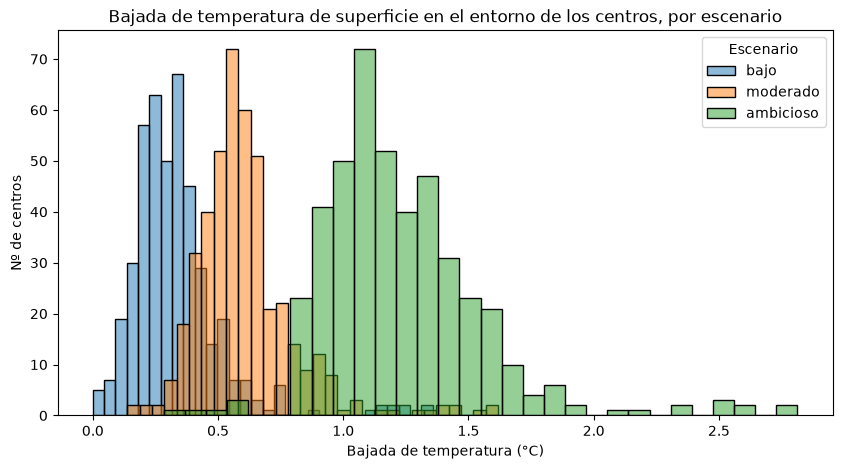

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for nombre in escenarios:
    sns.histplot(centros[f"bajada_{nombre}"], bins=30, label=nombre, alpha=0.5, ax=ax)
ax.set_title("Bajada de temperatura de superficie en el entorno de los centros, por escenario")
ax.set_xlabel("Bajada de temperatura (°C)")
ax.set_ylabel("Nº de centros")
ax.legend(title="Escenario")
plt.show()

**Observación:** las tres distribuciones están claramente separadas; la del escenario ambicioso es la más ancha (de 0,3 a 2,8 °C), porque el efecto depende mucho del entorno de cada centro.

- los 10 centros donde plantar tendría más efecto (escenario ambicioso)

In [12]:
centros.nlargest(10, "bajada_ambicioso")[["nombre", "tipo_centro", "plazas", "lst_actual", "bajada_bajo", "bajada_moderado", "bajada_ambicioso"]].round(2)

,nombre,tipo_centro,plazas,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
144,"AMAVIR VILLAVERDE, RESIDENCIA DE PERSONAS MAYO...",residencia,180.0,48.19,1.18,1.47,2.81
145,"AMAVIR VILLAVERDE, CENTRO DE DIA (PLAN VELOCIDAD)",centro de día,40.0,48.19,1.18,1.47,2.81
411,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VALL...,residencia,174.0,48.01,1.23,1.41,2.57
412,CENTRO DE DIA CASABLANCA VALLECAS,centro de día,30.0,48.01,1.23,1.41,2.57
436,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VICÁ...,residencia,192.0,47.76,1.36,1.62,2.54
437,CENTRO DE DÍA CASABLANCA VICÁLVARO,centro de día,40.0,47.76,1.36,1.62,2.54
47,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,601.0,46.91,1.15,1.55,2.54
45,"PLATA Y CASTAÑAR, RESIDENCIA DE PERSONAS MAYORES",residencia,220.0,44.33,0.62,0.86,2.31
46,"PLATA Y CASTAÑAR, CENTRO DE DIA",centro de día,45.0,44.33,0.62,0.86,2.31
407,RESIDENCIA DE PERSONAS MAYORES AMAVIR LA GAVIA,residencia,138.0,47.80,1.10,1.20,2.19


**Observación:** son sobre todo residencias y centros de día del sur y el sureste (Villaverde, Vallecas, Vicálvaro, La Gavia), con bajadas de 2,2 a 2,8 °C en el escenario ambicioso. Varios son residencias grandes (hasta 601 plazas).

- los 10 centros más calientes y su bajada en cada escenario

In [13]:
centros.nlargest(10, "lst_actual")[["nombre", "tipo_centro", "plazas", "lst_actual", "bajada_bajo", "bajada_moderado", "bajada_ambicioso"]].round(2)

,nombre,tipo_centro,plazas,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
144,"AMAVIR VILLAVERDE, RESIDENCIA DE PERSONAS MAYO...",residencia,180.0,48.19,1.18,1.47,2.81
145,"AMAVIR VILLAVERDE, CENTRO DE DIA (PLAN VELOCIDAD)",centro de día,40.0,48.19,1.18,1.47,2.81
411,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VALL...,residencia,174.0,48.01,1.23,1.41,2.57
412,CENTRO DE DIA CASABLANCA VALLECAS,centro de día,30.0,48.01,1.23,1.41,2.57
407,RESIDENCIA DE PERSONAS MAYORES AMAVIR LA GAVIA,residencia,138.0,47.80,1.10,1.20,2.19
436,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VICÁ...,residencia,192.0,47.76,1.36,1.62,2.54
437,CENTRO DE DÍA CASABLANCA VICÁLVARO,centro de día,40.0,47.76,1.36,1.62,2.54
388,RESIDENCIA DE PERSONAS MAYORES VITALIA CARABAN...,residencia,96.0,47.19,0.45,0.61,1.74
401,RESIDENCIA DE PERSONAS MAYORES EMERA CARABANCHEL,residencia,195.0,47.19,0.45,0.61,1.74
402,CENTRO DE DIA EMERA CARABANCHEL,centro de día,30.0,47.19,0.45,0.61,1.74


**Observación:** 7 de los 10 centros más calientes (de 47,2 a 48,2 °C) están también entre los que más bajarían con más arbolado. Los centros que más lo necesitan son también donde plantar rinde más, lo que apoya la hipótesis 3.

- guardamos los resultados por centro

In [14]:
centros.to_file(RUTA_CLEAN + "centros_simulacion.gpkg", driver="GPKG")
print(centros.shape)

(439, 17)


**Observación:** se guardan los 439 centros con su temperatura actual predicha y la bajada de cada escenario (17 columnas).

- comprobamos que la función de scrips/simulador.py da exactamente el mismo resultado que el notebook

In [16]:
centros_script = simular_centros()
print(centros_script.shape)
centros.equals(centros_script)

(439, 17)


True

**Observación:** la función del script da exactamente el mismo resultado que el notebook (439 centros y 17 columnas).